# Somatic CAG expansion by cell type & zone (simple threshold-and-average)

This notebook estimates, per donor / cell type / zone, how far the CAG repeat
has somatically expanded away from the length that donor actually inherited.

**Why not fit a Gaussian mixture?** A first version of this notebook fit a
2-component Gaussian mixture (GMM) to raw single-cell `CAGLENGTH` values,
anchored at the germline genotype. In practice, for small/noisy groups (one
cell type in one zone) the GMM fits were visibly wrong — peaks landing on
the wrong cluster, or nowhere near either real allele. Fitting a mixture
model is overkill here and too fragile on this data.

Instead, this notebook uses a much simpler, more robust rule, using the
germline genotype (`donor_metadata.txt`, mirrored in `adata.obs["CAG"]` as
e.g. `"15/42"`) as a fixed reference point rather than as a prior to fit
around:

1. Take every cell's `CAGLENGTH` in a group (donor x cell type, or
   donor x cell type x zone).
2. Keep only the values **greater than that donor's WT (inherited,
   non-expanded) length** — these are the molecules showing expansion.
3. **Average** those values. That average is the group's estimated expanded
   allele length; comparing it to the donor's inherited expanded length
   (`EXP_germline`) gives `expansion_shift`, the amount of *extra* (somatic)
   expansion in that group.

No distribution shape is assumed beyond "expansion means longer than WT" —
much easier to reason about, and only one number is estimated (the mean of
the expanded-looking reads), not a full mixture model.


## 1. Setup

In [50]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_context("notebook")


## 2. Load per-cell CAG-repeat length data (deep-dive PacBio)

Same source and filtering as `Handsaker_zone_repeat.ipynb`: keep only the
"deepdive" PacBio experiment, and only cells for which a `CAGLENGTH` was
measured.


In [51]:
adata = sc.read_h5ad(
    "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned.h5ad",
    backed="r",
)
mask = (adata.obs["experiment"] == "deepdive") & (adata.obs["CAGLENGTH"].notna() & (adata.obs["Status"] == "Case"))
adata = adata[mask].to_memory().copy()

adata.obs["DONOR"].value_counts()


DONOR
S06758    6910
S12365    5126
S05202    4841
S07681    2631
S02205    2376
S05368    1709
S09619    1506
S04002    1152
Name: count, dtype: int64

In [52]:
meta = adata.obs.drop_duplicates("DONOR").reset_index(drop=True)
meta.index = meta["DONOR"]
meta["Status"]

DONOR
S02205    Case
S04002    Case
S05202    Case
S05368    Case
S06758    Case
S07681    Case
S09619    Case
S12365    Case
Name: Status, dtype: category
Categories (1, object): ['Case']

### Optional: drop anomalously long reads

Some single-cell `CAGLENGTH` calls reach into the hundreds of repeats (likely
mis-mapped/chimeric reads rather than real biology). Toggle
`EXCLUDE_LONG_READS` to re-run the whole analysis while dropping any read
longer than `MAX_CAGLENGTH`, to check how much those extreme values are
driving the results.


In [18]:
# EXCLUDE_LONG_READS = True   # set to False to keep every read regardless of length
# MAX_CAGLENGTH = 140         # only used when EXCLUDE_LONG_READS is True

# if EXCLUDE_LONG_READS:
#     n_before = adata.n_obs
#     adata = adata[adata.obs["CAGLENGTH"] <= MAX_CAGLENGTH].copy()
#     print(f"dropped {n_before - adata.n_obs} / {n_before} cells with CAGLENGTH > {MAX_CAGLENGTH}")


## 3. Each donor's germline (inherited) CAG lengths — the prior

`adata.obs["CAG"]` carries the bulk clinical genotype for each donor as a
string like `"15/42"` (two alleles, one per copy of chromosome 4 — see the
diploid explanation from our discussion). We split that into:

- `WT_germline`  — the shorter, non-expanded allele (assumed stable)
- `EXP_germline` — the longer allele (this is what somatically expands)

For a homozygous donor (e.g. a control with `"17/17"`) both values end up
equal — that's expected, and acts as a useful negative control later on
(no real "expanded" peak should be found).


In [53]:
germline = (
    adata.obs[["DONOR", "CAG"]]
    .drop_duplicates()
    .dropna()
    .assign(CAG=lambda d: d["CAG"].astype(str))
)
germline[["allele_a", "allele_b"]] = germline["CAG"].str.split("/", expand=True).astype(int)
germline["WT_germline"] = germline[["allele_a", "allele_b"]].min(axis=1)
germline["EXP_germline"] = germline[["allele_a", "allele_b"]].max(axis=1)
germline = germline.set_index("DONOR")[["WT_germline", "EXP_germline"]]

germline["Status"] = meta.loc[germline.index, "Status"]

germline


,WT_germline,EXP_germline,Status
DONOR,,,
S02205,20,42,Case
S04002,17,42,Case
S05202,15,42,Case
S05368,16,39,Case
S06758,18,43,Case
S07681,16,42,Case
S09619,22,37,Case
S12365,17,40,Case


In [54]:
adata.obs = adata.obs.merge(germline[["WT_germline", "EXP_germline"]], left_on="DONOR", right_index=True)
adata.obs

,reaction,experiment,CELL_BARCODE,DONOR,SID,Age,Sex,Status,CAG,PMI,...,Cluster_aggregate_probability,Cluster_correlation_coefficient,mapping_coupling_for_zoning,zone,zone_probability,mapping_coupling_for_zoning_4_zones,zone_4,zone_4_probability,WT_germline,EXP_germline
S02205_Caudate_DeepDive_rxn1_TCCTAATTCCACGGAC,S02205_Caudate_DeepDive_rxn1,deepdive,S02205_Caudate_DeepDive_rxn1_TCCTAATTCCACGGAC,S02205,S02205,48,Female,Case,20/42,30.80,...,0.9900,0.7570,STR D2 Matrix MSN,3,0.673,NaN,NaN,NaN,20,42
S02205_Caudate_DeepDive_rxn1_GAGACCCAGCCATATC,S02205_Caudate_DeepDive_rxn1,deepdive,S02205_Caudate_DeepDive_rxn1_GAGACCCAGCCATATC,S02205,S02205,48,Female,Case,20/42,30.80,...,0.7500,0.4700,NaN,NaN,NaN,STRd D1 Striosome MSN 4 zones,2,0.975,20,42
S02205_Caudate_DeepDive_rxn1_TTCCTTCCAGCACGAA,S02205_Caudate_DeepDive_rxn1,deepdive,S02205_Caudate_DeepDive_rxn1_TTCCTTCCAGCACGAA,S02205,S02205,48,Female,Case,20/42,30.80,...,0.5005,0.5239,STR D2 Matrix MSN,2,0.852,NaN,NaN,NaN,20,42
S02205_Caudate_DeepDive_rxn1_TTCCTAAGTGGTTTAC,S02205_Caudate_DeepDive_rxn1,deepdive,S02205_Caudate_DeepDive_rxn1_TTCCTAAGTGGTTTAC,S02205,S02205,48,Female,Case,20/42,30.80,...,0.9100,0.5158,STR D1 Matrix MSN,2,1.000,NaN,NaN,NaN,20,42
S02205_Caudate_DeepDive_rxn1_AGCTACATCGAACACT,S02205_Caudate_DeepDive_rxn1,deepdive,S02205_Caudate_DeepDive_rxn1_AGCTACATCGAACACT,S02205,S02205,48,Female,Case,20/42,30.80,...,0.5580,0.6630,STR D2 Matrix MSN,3,0.998,NaN,NaN,NaN,20,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
S12365_Caudate_DeepDive_rxn4_TGTGCGGTCGGACGTC,S12365_Caudate_DeepDive_rxn4,deepdive,S12365_Caudate_DeepDive_rxn4_TGTGCGGTCGGACGTC,S12365,S12365,81,Female,Case,17/40,17.33,...,0.4588,0.5476,NaN,NaN,NaN,NaN,NaN,NaN,17,40
S12365_Caudate_DeepDive_rxn4_AGGTCATCAATAGTCC,S12365_Caudate_DeepDive_rxn4,deepdive,S12365_Caudate_DeepDive_rxn4_AGGTCATCAATAGTCC,S12365,S12365,81,Female,Case,17/40,17.33,...,1.0000,0.6028,NaN,NaN,NaN,NaN,NaN,NaN,17,40
S12365_Caudate_DeepDive_rxn4_TCCATCGGTGGACAGT,S12365_Caudate_DeepDive_rxn4,deepdive,S12365_Caudate_DeepDive_rxn4_TCCATCGGTGGACAGT,S12365,S12365,81,Female,Case,17/40,17.33,...,0.5280,0.5218,NaN,NaN,NaN,Astrocyte 4 zones,4,0.626,17,40
S12365_Caudate_DeepDive_rxn4_CTGGACGCAATTCGTG,S12365_Caudate_DeepDive_rxn4,deepdive,S12365_Caudate_DeepDive_rxn4_CTGGACGCAATTCGTG,S12365,S12365,81,Female,Case,17/40,17.33,...,0.5000,0.4329,NaN,NaN,NaN,Astrocyte 4 zones,2,0.646,17,40


## 4. Build cell type and cell type x zone grouping columns

Some cells were zoned with a 6-zone scheme, others with a 4-zone scheme
(depending on which mapping was available). We merge both into one
`celltype_zoning` / `zone_mixed` pair of columns, exactly as in
`Handsaker_zone_repeat.ipynb`, so the two notebooks stay comparable.


In [55]:
has_zone_6 = adata.obs["mapping_coupling_for_zoning"].notna()
has_zone_4 = adata.obs["mapping_coupling_for_zoning_4_zones"].notna()

adata.obs["celltype_zoning"] = pd.Series(index=adata.obs.index, dtype=object)
adata.obs["zone_mixed"] = pd.Series(index=adata.obs.index, dtype=object)

adata.obs.loc[has_zone_6, "celltype_zoning"] = adata.obs.loc[has_zone_6, "mapping_coupling_for_zoning"].astype(str)
adata.obs.loc[has_zone_4, "celltype_zoning"] = adata.obs.loc[has_zone_4, "mapping_coupling_for_zoning_4_zones"].astype(str)
adata.obs["celltype_zoning"] = adata.obs["celltype_zoning"].str.replace(" 4 zones", "", regex=False)

adata.obs.loc[has_zone_6, "zone_mixed"] = adata.obs.loc[has_zone_6, "zone"].astype(str)
adata.obs.loc[has_zone_4, "zone_mixed"] = adata.obs.loc[has_zone_4, "zone_4"].astype(str)

# drop cells that couldn't be zoned at all
adata = adata[adata.obs["zone_mixed"].notna() & (adata.obs["zone_mixed"] != "nan")].copy()

# focus on the most abundant cell types, same as the exploratory notebook
ct_to_check = adata.obs["celltype_zoning"].value_counts().index[:6].tolist()
all_zones = sorted(adata.obs["zone_mixed"].unique())

print("Cell types analysed:", ct_to_check)
print("Zones analysed:", all_zones)


Cell types analysed: ['STR D1 Matrix MSN', 'Astrocyte', 'STR D2 Matrix MSN', 'STRd D1 Striosome MSN', 'STRd D2 Striosome MSN', 'STR D1D2 Hybrid MSN']
Zones analysed: ['1', '2', '3', '4', '5', '6']


/tmp/ipykernel_21303/3728937444.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["celltype_zoning", "DONOR", "zone_mixed"])
/tmp/ipykernel_21303/3728937444.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts.groupby(["celltype_zoning", "DONOR"])["n_cells"]


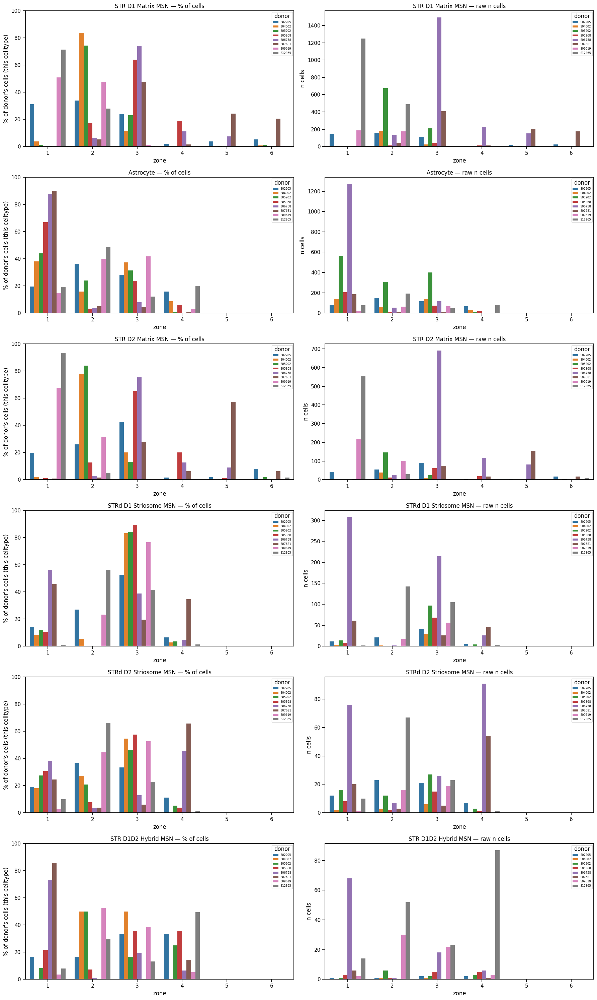

In [41]:
counts = (
    adata.obs
    .groupby(["celltype_zoning", "DONOR", "zone_mixed"])
    .size()
    .reset_index(name="n_cells")
)

counts["pct_cells"] = (
    counts.groupby(["celltype_zoning", "DONOR"])["n_cells"]
    .transform(lambda x: 100 * x / x.sum())
)   # normalize within each (celltype, donor): zones sum to 100% per donor

all_zones = sorted(adata.obs["zone_mixed"].unique())
n_ct = len(ct_to_check)

fig, axes = plt.subplots(n_ct, 2, figsize=(18, 5 * n_ct), squeeze=False)   # col 0 = %, col 1 = raw n_cells

for i, ct in enumerate(ct_to_check):
    sub = counts[counts["celltype_zoning"] == ct]

    ax = axes[i, 0]
    sns.barplot(data=sub, x="zone_mixed", y="pct_cells", hue="DONOR", order=all_zones, ax=ax)
    ax.set_title(f"{ct} — % of cells")
    ax.set_ylim(0, 100)
    ax.set_xlabel("zone")
    ax.set_ylabel("% of donor's cells (this celltype)")
    ax.legend(fontsize=6, title="donor")

    ax = axes[i, 1]
    sns.barplot(data=sub, x="zone_mixed", y="n_cells", hue="DONOR", order=all_zones, ax=ax)
    ax.set_title(f"{ct} — raw n cells")
    ax.set_xlabel("zone")
    ax.set_ylabel("n cells")
    ax.legend(fontsize=6, title="donor")

plt.tight_layout()
plt.show()


## 5. Expansion estimate: average of the CAGLRNGHTS cells longer than the WT allele


In [49]:
# --- tunable knobs -----------------------------------------------------
MIN_CELLS = 5     # skip groups with fewer cells than this
OUTLIER_PCT = 99   # trim the top percentile of CAGLENGTH before averaging (mis-mapped reads etc.)
# -------------------------------------------------------------------------


def summarize_expansion(cag_lengths, exp_prior, min_cells=MIN_CELLS, outlier_pct=OUTLIER_PCT):
    """Estimate somatic expansion in one group as the mean of the CAGLENGTHS longer than the donor's germline WT length.

    Returns a dict of summary stats, or None if there aren't enough cells,
    or none of them show any length above WT, to say anything meaningful.
    """
    x = np.asarray(cag_lengths, dtype=float)
    x = x[~np.isnan(x)]

    if len(x) < min_cells:
        return None

    # trim extreme outliers before averaging
    cutoff = np.percentile(x, outlier_pct)
    x = x[x <= cutoff]

    expanded = x[x > exp_prior]
    if len(expanded) == 0:
        return None

    mean_expanded = np.percentile(expanded, 50)  # median

    return dict(
        n_cells=len(x),
        n_expanded=len(expanded),
        frac_expanded=len(expanded) / len(x),
        mean_expanded=mean_expanded,
        # the quantity of interest: extra expansion beyond what was inherited
        expansion_shift=mean_expanded,
    )


## 6. Fit per donor x cell type x zone

One row per (donor, cell type) with enough cells, pooling all zones.


In [50]:
celltype_rows = []
celltype_zone_rows = []

for donor, donor_obs in adata.obs.groupby("DONOR"):
    if donor not in germline.index:
        continue
    wt_prior = germline.loc[donor, "WT_germline"]
    exp_prior = germline.loc[donor, "EXP_germline"]

    for ct in ct_to_check:
        ct_obs = donor_obs[donor_obs["celltype_zoning"] == ct]

        # pooled across all zones
        fit = summarize_expansion(ct_obs["CAGLENGTH"].values, wt_prior, exp_prior)
        if fit is not None:
            celltype_rows.append(dict(DONOR=donor, celltype=ct, WT_germline=wt_prior, EXP_germline=exp_prior, **fit))

        # per zone
        for zone in all_zones:
            x = ct_obs.loc[ct_obs["zone_mixed"] == zone, "CAGLENGTH"].values
            fit = summarize_expansion(x, wt_prior, exp_prior)
            if fit is None:
                continue
            celltype_zone_rows.append(dict(
                DONOR=donor, celltype=ct, zone=zone,
                WT_germline=wt_prior, EXP_germline=exp_prior, **fit,
            ))

celltype_results = pd.DataFrame(celltype_rows)
celltype_zone_results = pd.DataFrame(celltype_zone_rows)
celltype_results
celltype_zone_results

/tmp/ipykernel_21303/3030029220.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for donor, donor_obs in adata.obs.groupby("DONOR"):


,DONOR,celltype,zone,WT_germline,EXP_germline,n_cells,n_expanded,frac_expanded,mean_expanded,expansion_shift
0,S02205,STR D1 Matrix MSN,1,20,42,143,75,0.524476,69.0,69.0
1,S02205,STR D1 Matrix MSN,2,20,42,156,88,0.564103,65.0,65.0
2,S02205,STR D1 Matrix MSN,3,20,42,110,68,0.618182,67.5,67.5
3,S02205,Astrocyte,1,20,42,81,44,0.543210,42.0,42.0
4,S02205,Astrocyte,2,20,42,149,71,0.476510,42.0,42.0
...,...,...,...,...,...,...,...,...,...,...
65,S12365,STRd D1 Striosome MSN,2,17,40,140,83,0.592857,57.0,57.0
66,S12365,STRd D1 Striosome MSN,3,17,40,103,53,0.514563,63.0,63.0
67,S12365,STRd D2 Striosome MSN,2,17,40,66,39,0.590909,60.0,60.0
68,S12365,STR D1D2 Hybrid MSN,2,17,40,51,34,0.666667,61.5,61.5


## 8. QC plots: raw CAGLENGTH vs. germline vs. mean of expanded reads

For each donor and cell type, this overlays the raw `CAGLENGTH` histogram
with: the germline genotype (grey, dashed — the two inherited allele
lengths), and `mean_expanded` (red, solid — the average of the reads that
fell above the WT length, i.e. the estimate actually used).


/tmp/ipykernel_21303/742875092.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for donor, donor_obs in adata.obs.groupby("DONOR"):


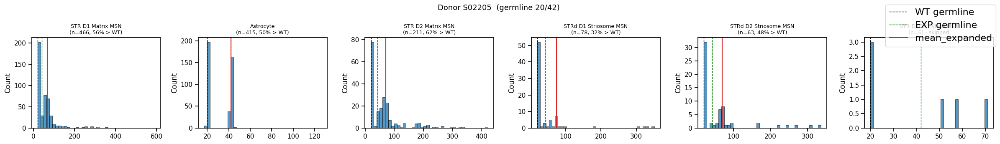

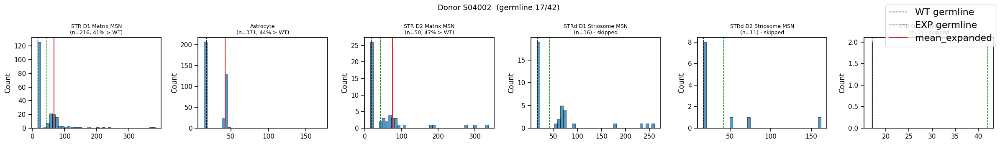

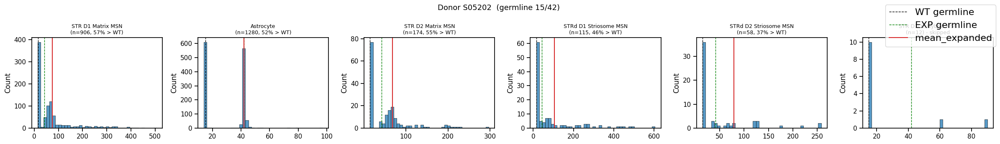

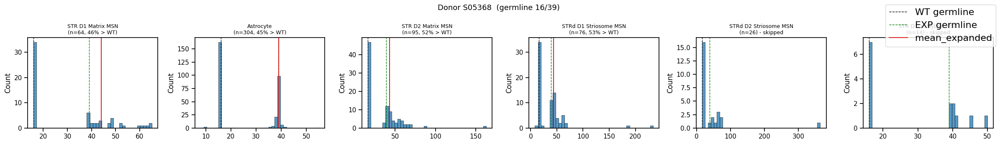

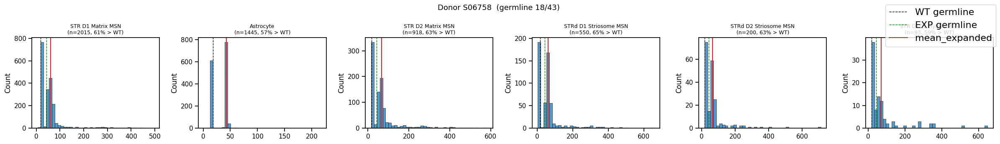

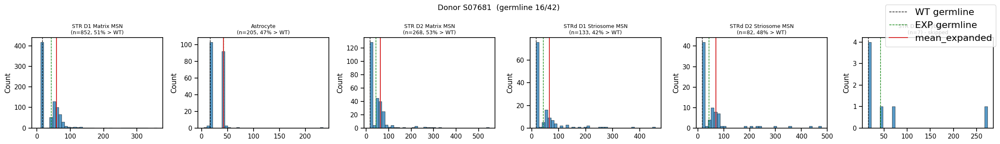

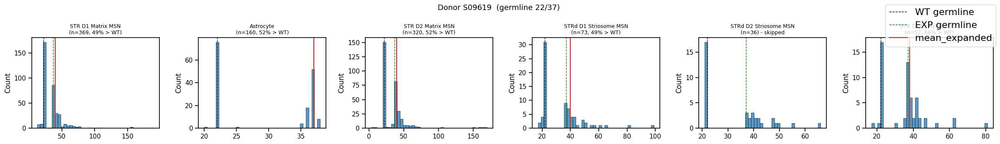

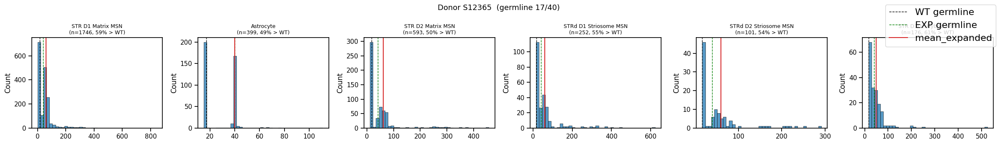

In [53]:
for donor, donor_obs in adata.obs.groupby("DONOR"):
    if donor not in germline.index:
        continue
    wt_prior = germline.loc[donor, "WT_germline"]
    exp_prior = germline.loc[donor, "EXP_germline"]

    fig, axes = plt.subplots(1, len(ct_to_check), figsize=(4 * len(ct_to_check), 3.5), squeeze=False)
    fig.suptitle(f"Donor {donor}  (germline {wt_prior}/{exp_prior})", fontsize=13)

    for ax, ct in zip(axes[0], ct_to_check):
        x = donor_obs.loc[donor_obs["celltype_zoning"] == ct, "CAGLENGTH"].values
        fit = summarize_expansion(x, wt_prior, exp_prior)

        sns.histplot(x, bins=40, ax=ax)
        ax.axvline(wt_prior, color="black", linestyle="--", linewidth=1, label="WT germline")
        ax.axvline(exp_prior, color="green", linestyle="--", linewidth=1, label="EXP germline")
        if fit is not None:
            ax.axvline(fit["mean_expanded"], color="tab:red", linestyle="-", linewidth=1.5, label="mean_expanded")
            ax.set_title(f"{ct}\n(n={len(x)}, {fit['frac_expanded']:.0%} > WT)", fontsize=9)
        else:
            ax.set_title(f"{ct}\n(n={len(x)}) - skipped", fontsize=9)

    # single shared legend (avoid repeating it on every panel)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    fig.legend(by_label.values(), by_label.keys(), loc="upper right", fontsize=16)

    plt.tight_layout()
    plt.show()


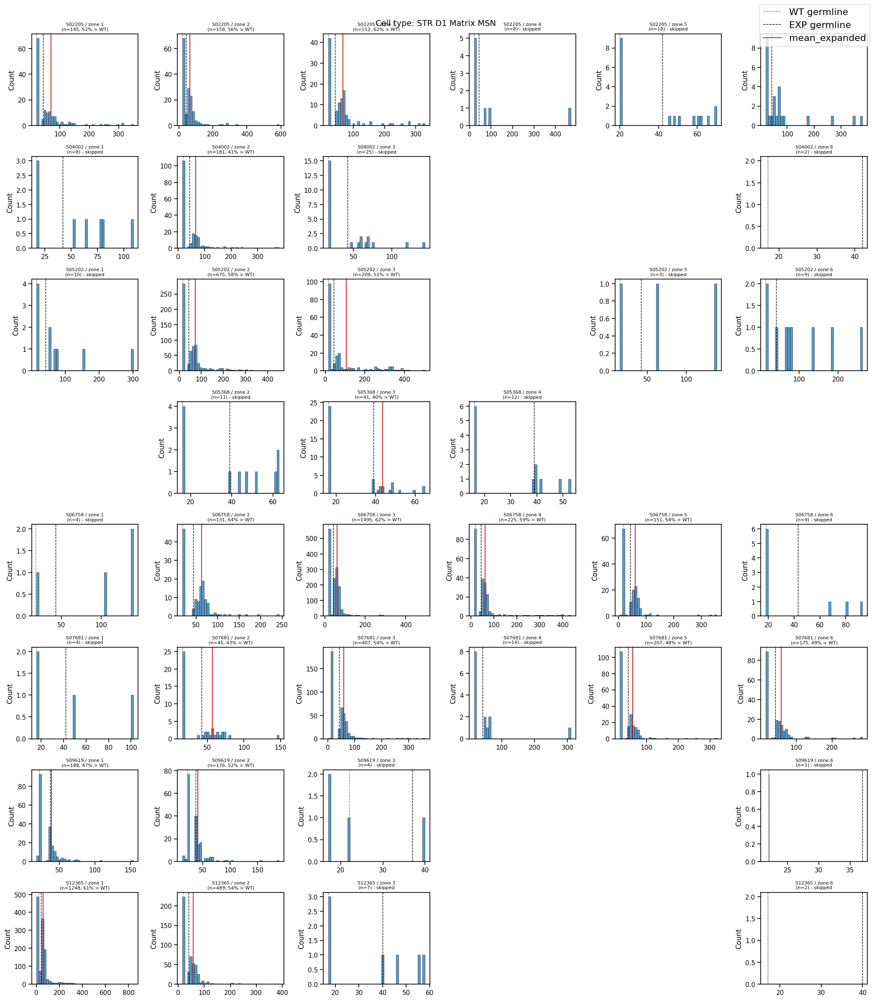

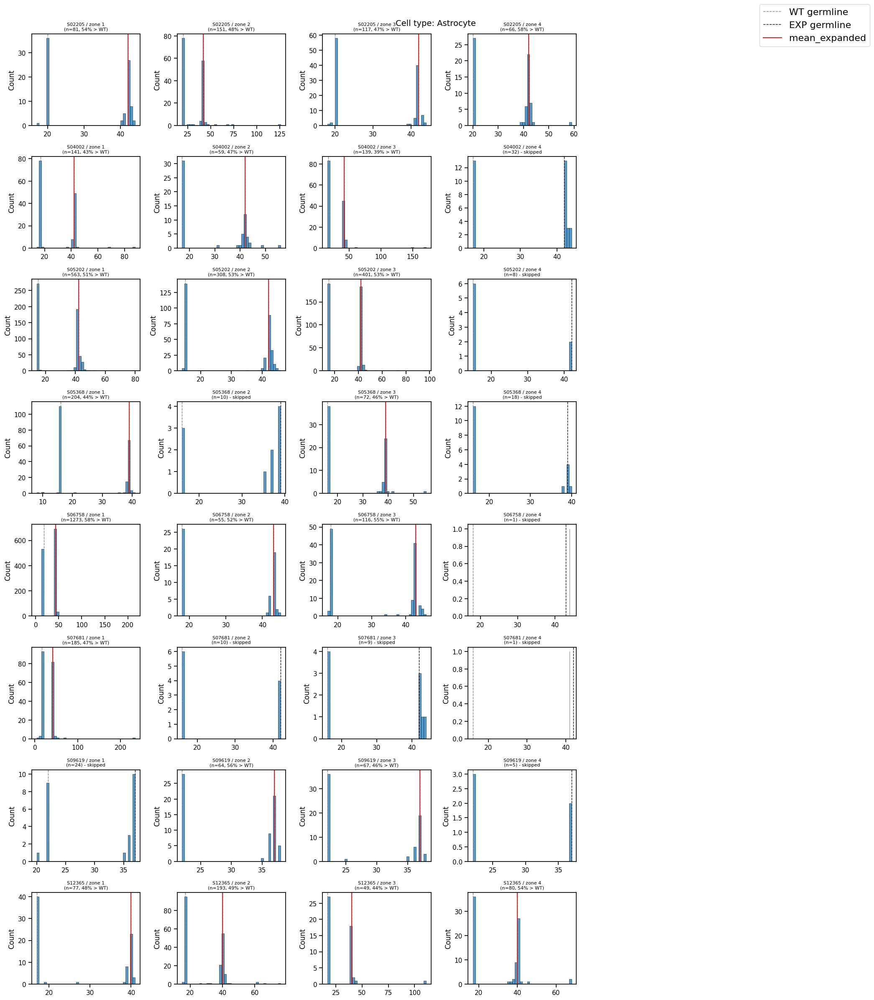

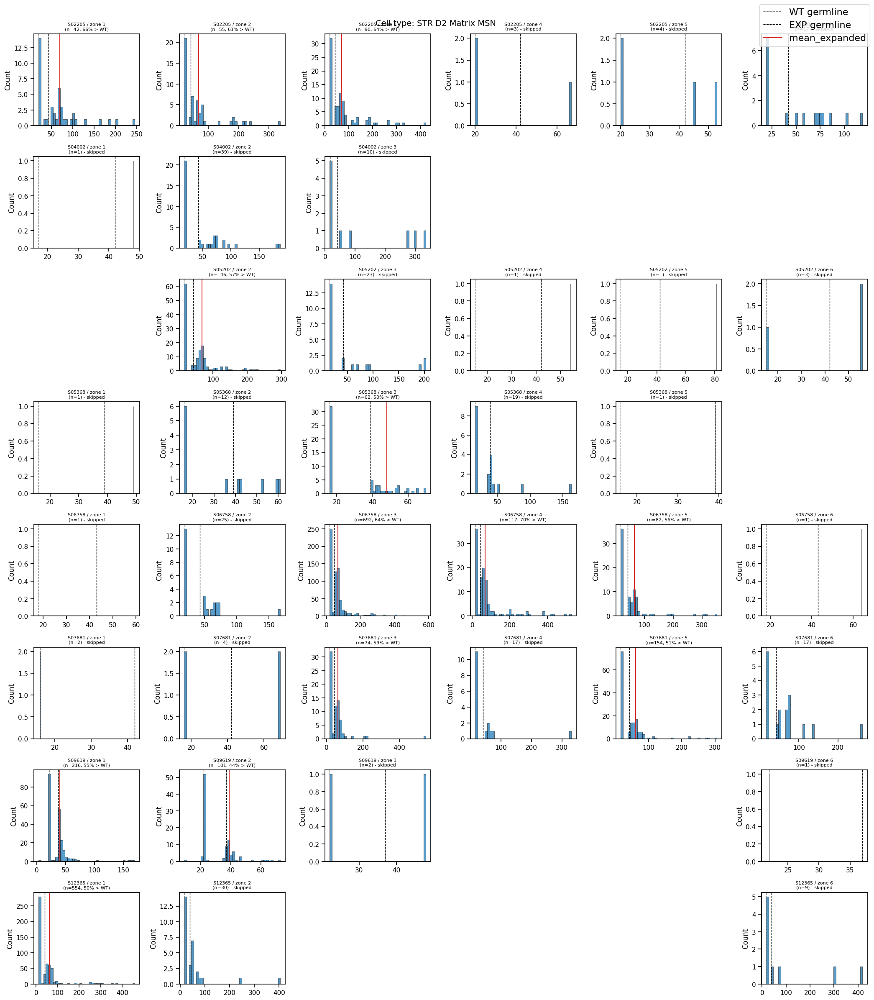

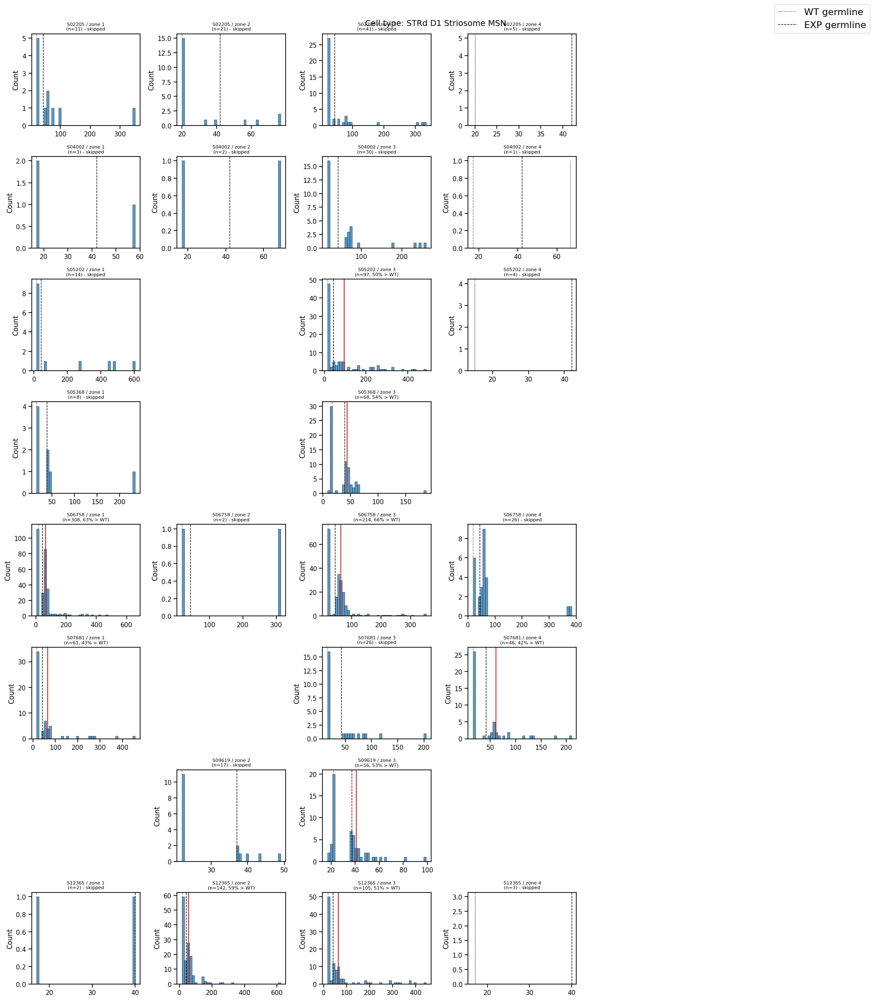

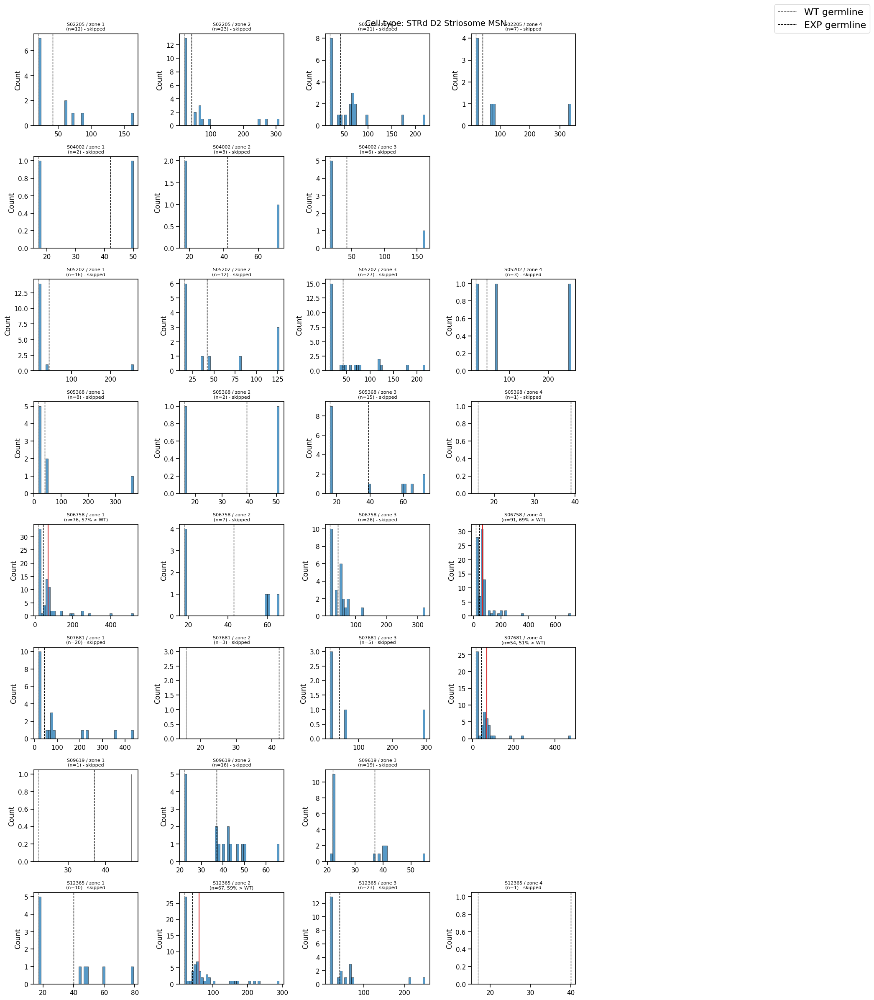

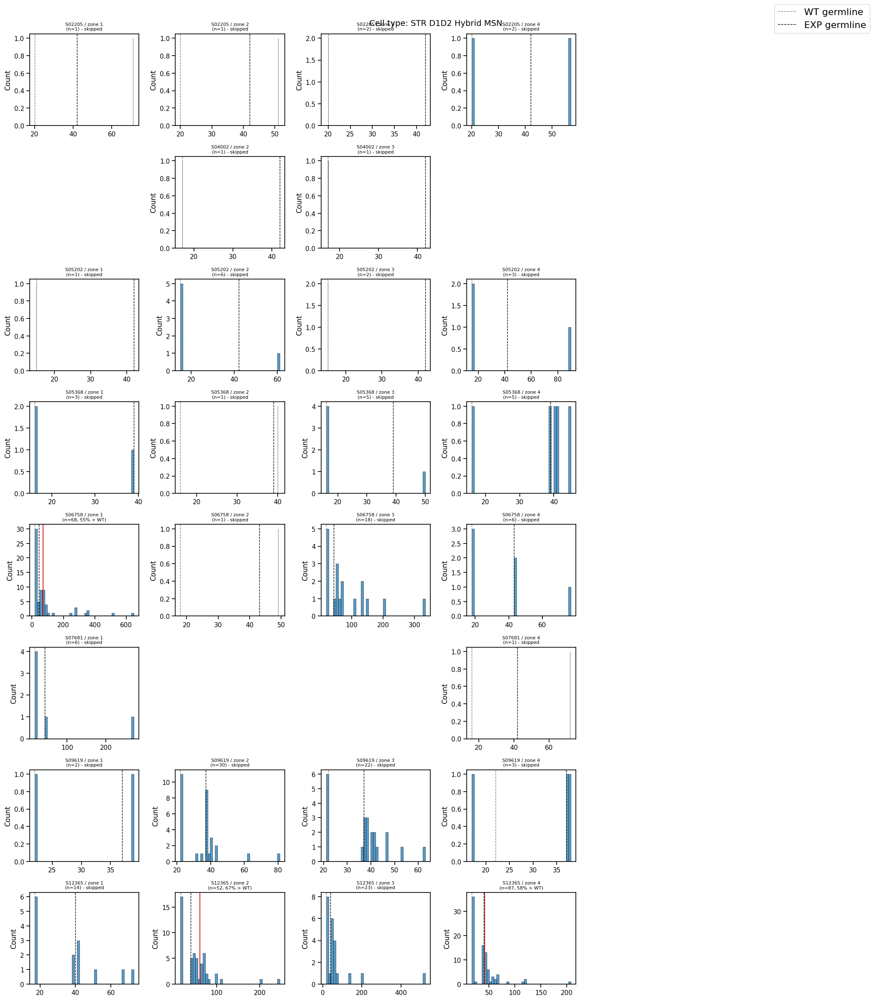

In [60]:
for ct in ct_to_check:
    ct_obs_all = adata.obs[adata.obs["celltype_zoning"] == ct]
    donors_with_ct = [d for d in germline.index if d in ct_obs_all["DONOR"].unique()]

    fig, axes = plt.subplots(
        len(donors_with_ct), len(all_zones),
        figsize=(3.5 * len(all_zones), 3 * len(donors_with_ct)),
        squeeze=False,
    )
    fig.suptitle(f"Cell type: {ct}", fontsize=14)

    legend_handles, legend_labels = None, None

    for row, donor in enumerate(donors_with_ct):
        wt_prior = germline.loc[donor, "WT_germline"]
        exp_prior = germline.loc[donor, "EXP_germline"]
        donor_ct_obs = ct_obs_all[ct_obs_all["DONOR"] == donor]

        for col, zone in enumerate(all_zones):
            ax = axes[row, col]
            x = donor_ct_obs.loc[donor_ct_obs["zone_mixed"] == zone, "CAGLENGTH"].values

            # no cells for this donor/zone combo -> leave the panel blank
            if len(x) == 0:
                ax.axis("off")
                continue

            fit = summarize_expansion(x, wt_prior, exp_prior)

            sns.histplot(x, bins=40, ax=ax)
            ax.axvline(wt_prior, color="grey", linestyle="--", linewidth=1, label="WT germline")
            ax.axvline(exp_prior, color="black", linestyle="--", linewidth=1, label="EXP germline")
            if fit is not None:
                ax.axvline(fit["mean_expanded"], color="tab:red", linestyle="-", linewidth=1.5, label="mean_expanded")
                ax.set_title(f"{donor} / zone {zone}\n(n={len(x)}, {fit['frac_expanded']:.0%} > WT)", fontsize=8)
            else:
                ax.set_title(f"{donor} / zone {zone}\n(n={len(x)}) - skipped", fontsize=8)

            # grab the legend from the first panel that actually plotted something
            if legend_handles is None:
                legend_handles, legend_labels = ax.get_legend_handles_labels()

    if legend_handles is not None:
        by_label = dict(zip(legend_labels, legend_handles))
        fig.legend(by_label.values(), by_label.keys(), loc="upper right", fontsize=16)

    plt.tight_layout()
    plt.show()


## 9. Summary: expansion by cell type, and by zone within cell type

`expansion_shift` is the quantity of interest: how far the average
expanded-looking read sits beyond the length that was actually inherited
(`mean_expanded - EXP_germline`). `frac_expanded` (fraction of reads above
WT length) is worth checking alongside it — a high `expansion_shift` based
on only a handful of expanded reads (low `frac_expanded`, small `n_expanded`)
is much less reliable than one backed by most of the group's reads.


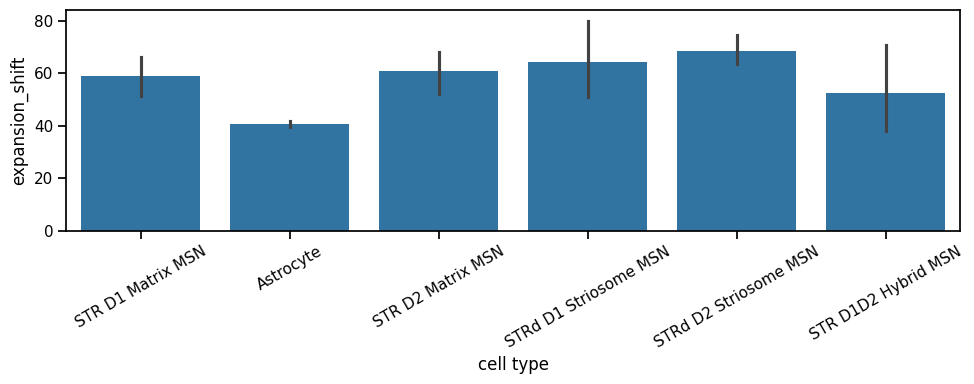

In [62]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=celltype_results, x="celltype", y="expansion_shift", ax=ax)
ax.set_ylabel("expansion_shift")
ax.set_xlabel("cell type")
ax.tick_params(axis="x", rotation=30)
# ax.legend(fontsize=7, title="donor", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


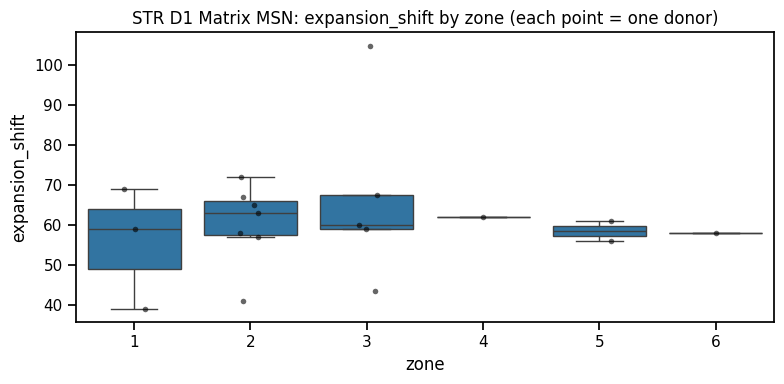

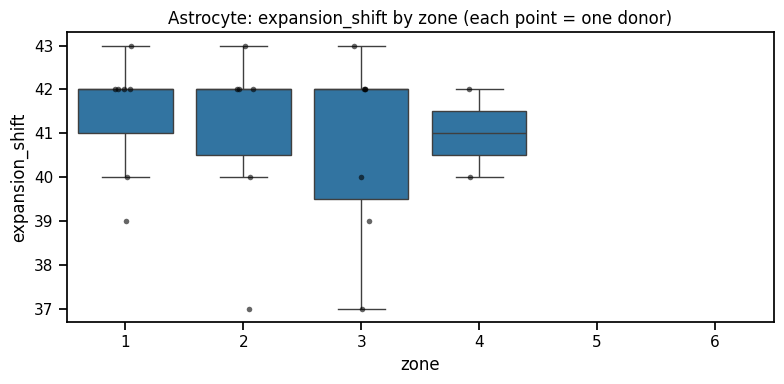

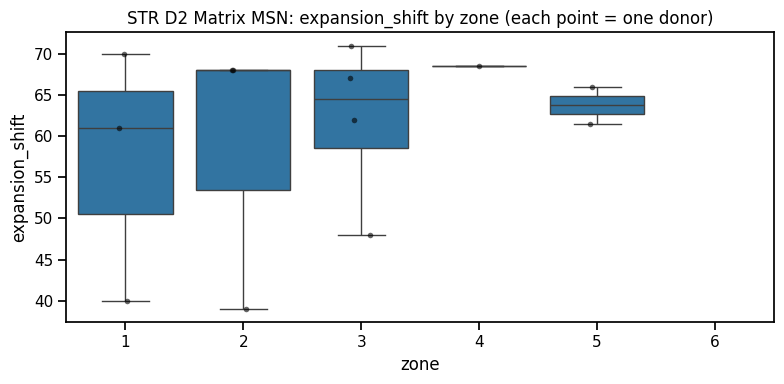

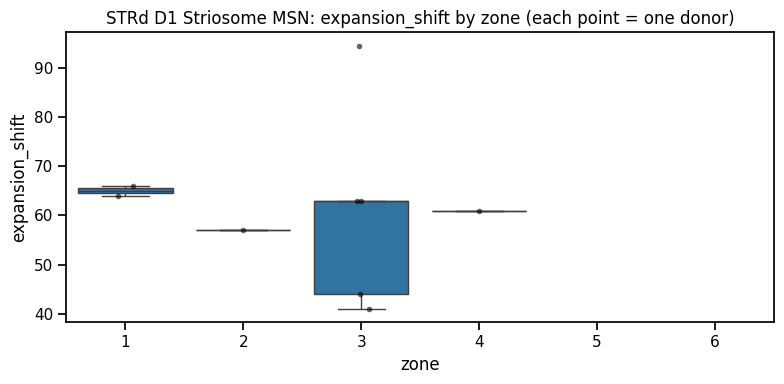

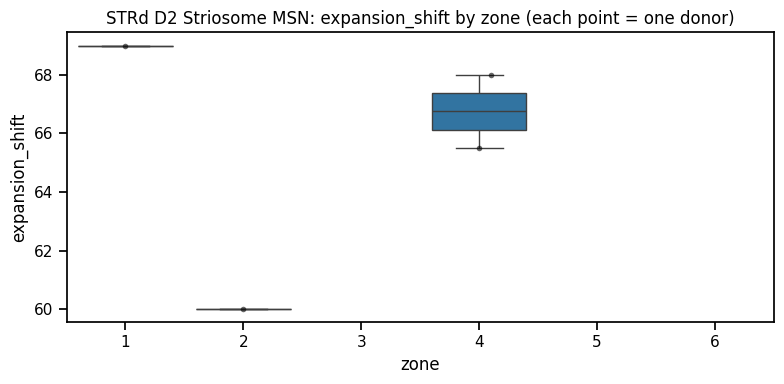

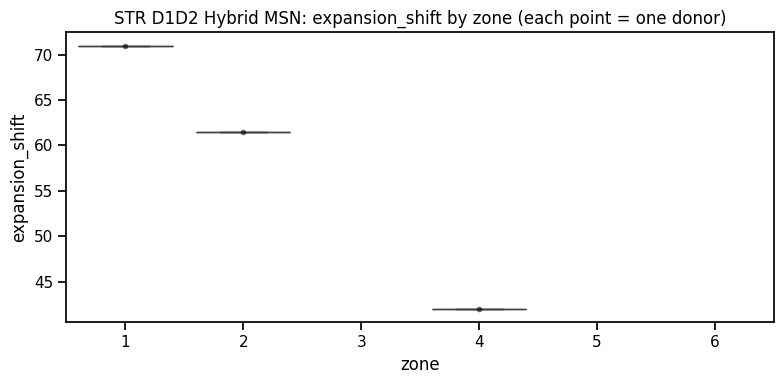

In [56]:
for ct in ct_to_check:
    sub = celltype_zone_results[celltype_zone_results["celltype"] == ct]
    if sub["zone"].nunique() < 2:
        print(f"skipping {ct}: fewer than 2 zones with data")
        continue

    fig, ax = plt.subplots(figsize=(8, 4))
    sns.boxplot(data=sub, x="zone", y="expansion_shift", order=all_zones, ax=ax, showfliers=False)
    sns.stripplot(data=sub, x="zone", y="expansion_shift", order=all_zones, ax=ax, color="black", size=4, alpha=0.6)
    ax.set_title(f"{ct}: expansion_shift by zone (each point = one donor)")
    ax.set_ylabel("expansion_shift")
    plt.tight_layout()
    plt.show()


## 10. Zone vs zone comparison (pairwise scatter, each point = one donor)

For each cell type, pivot `expansion_shift` to one row per donor and one
column per zone, then scatter every pair of zones against each other. If
expansion didn't differ by zone, points would sit on the grey y=x line;
systematic deviation from it means that pair of zones differs consistently
across donors.

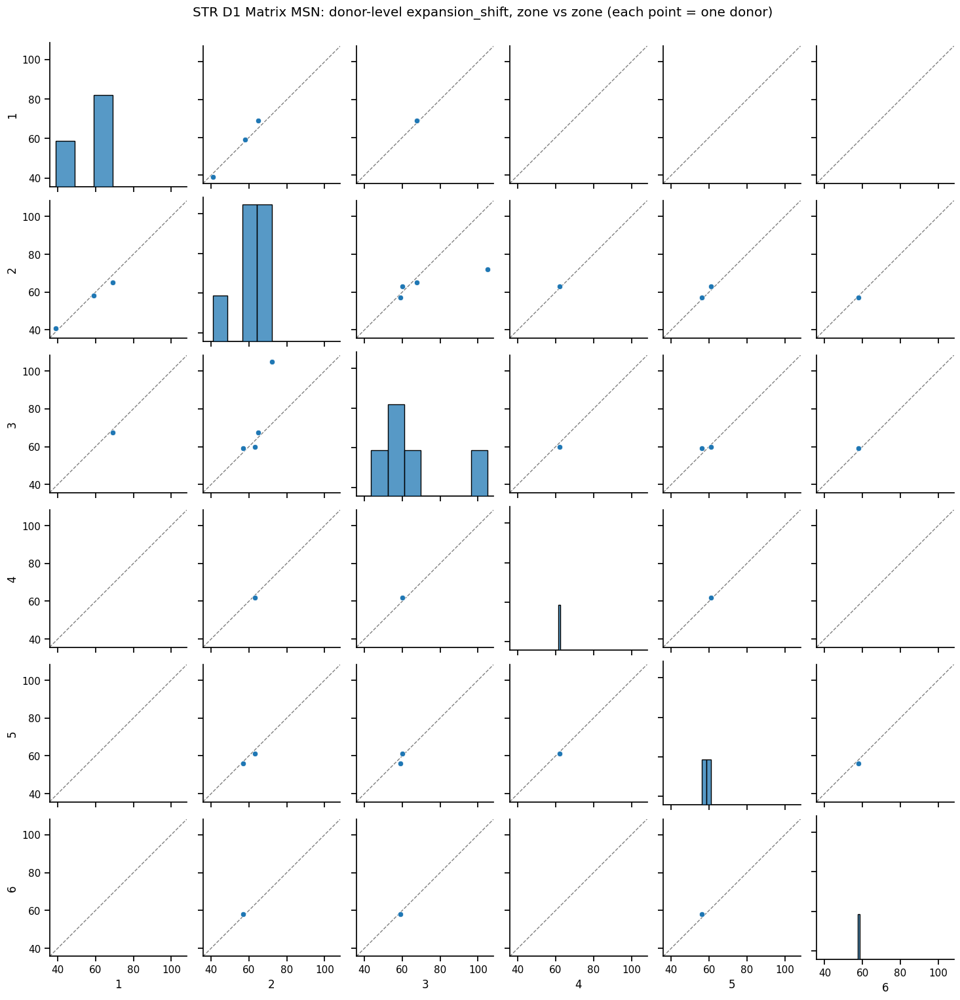

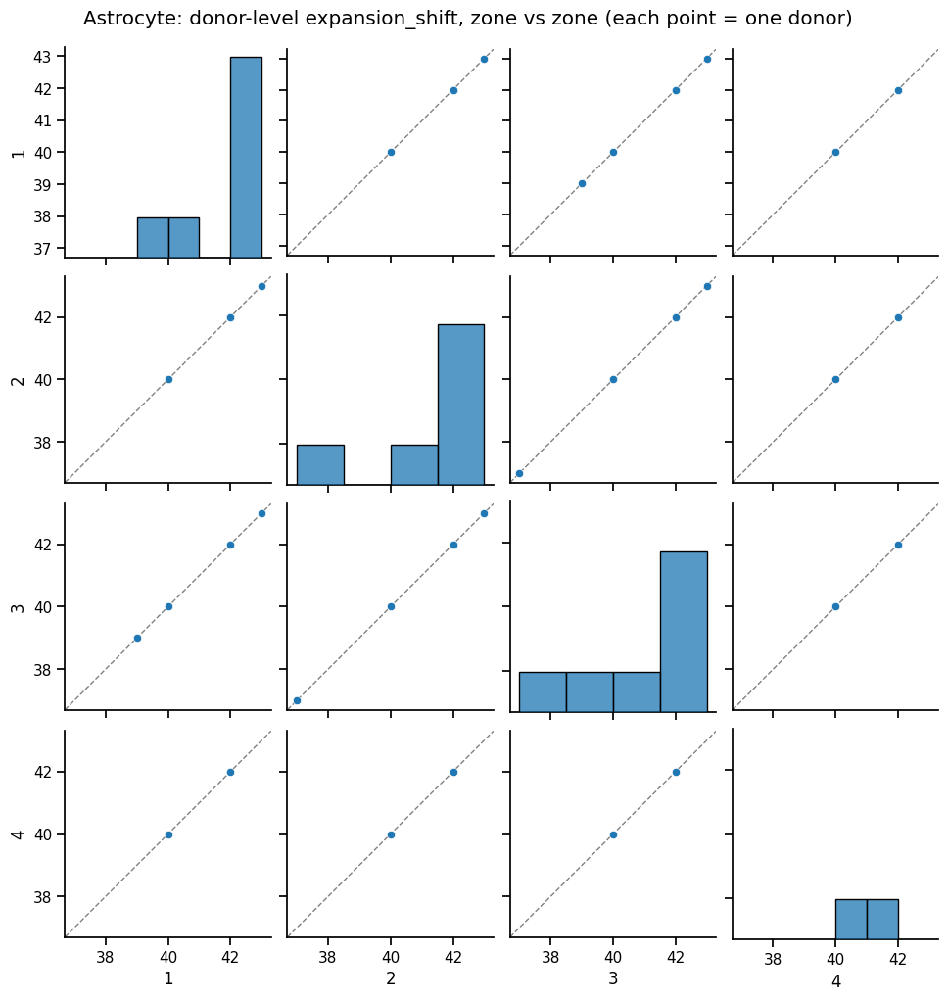

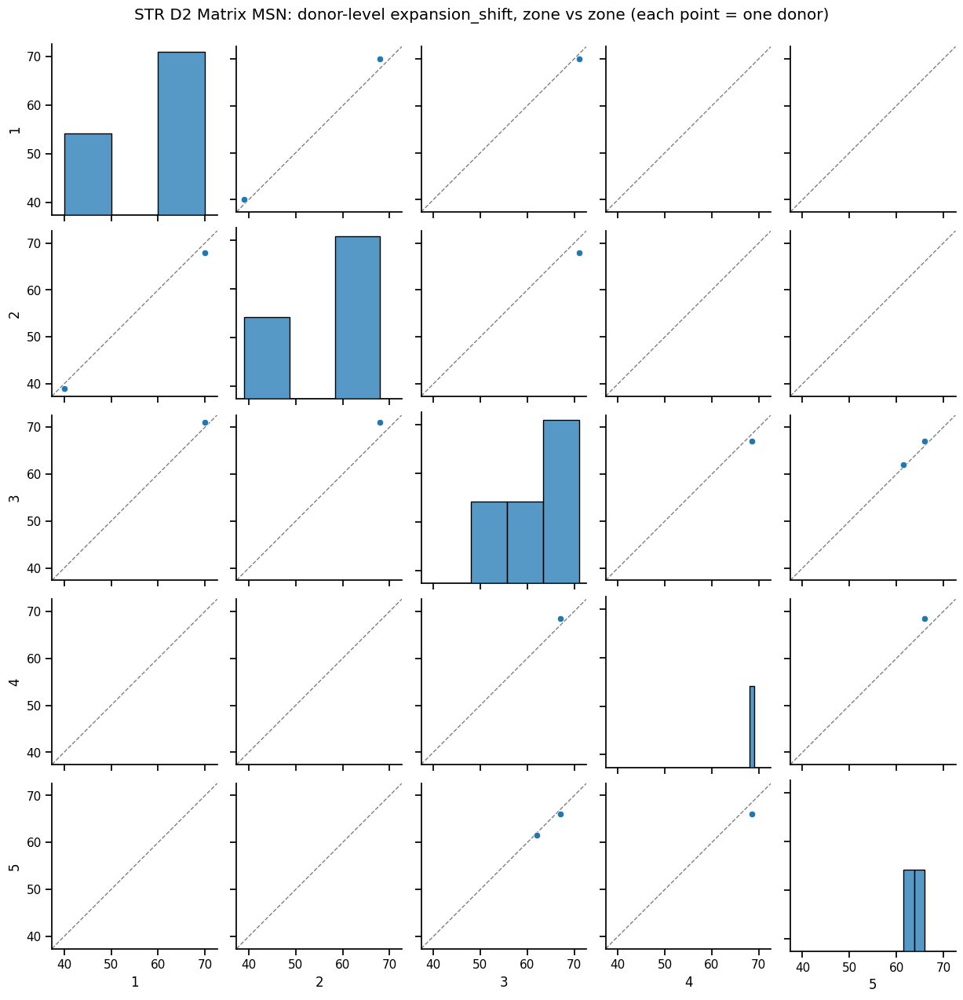

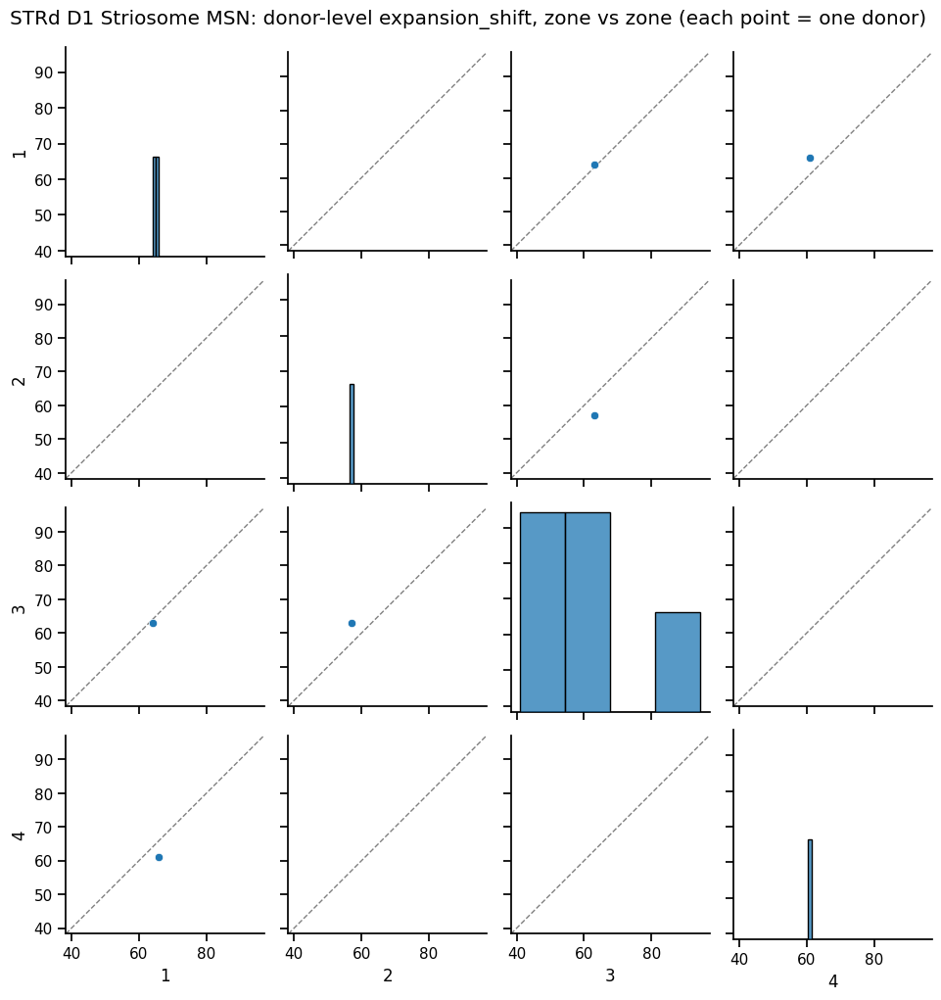

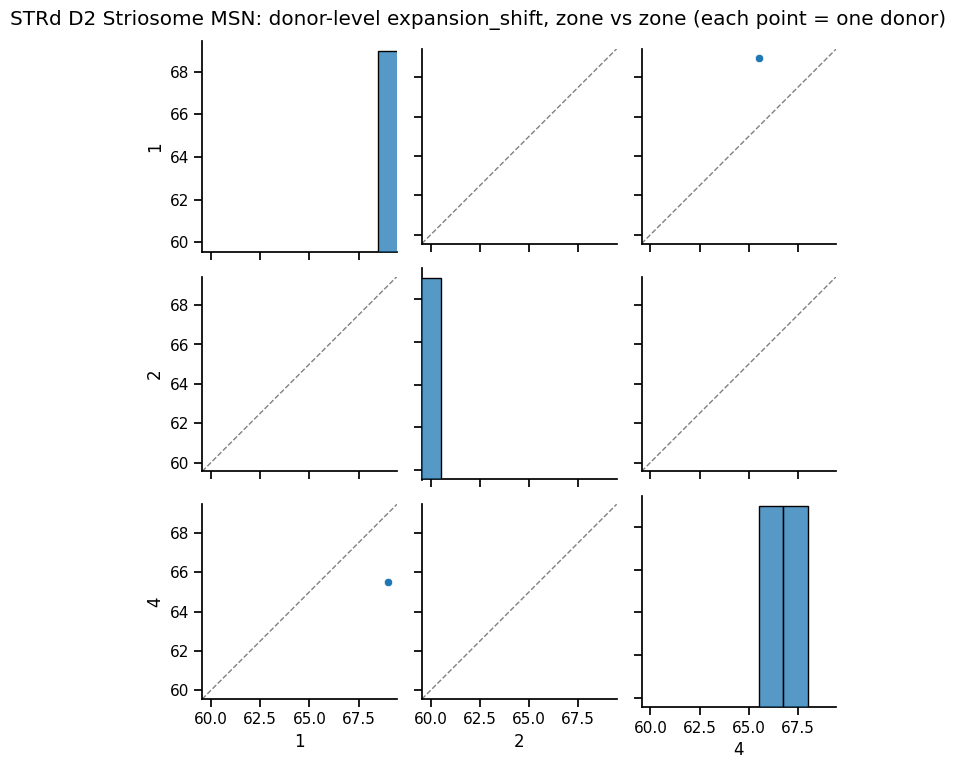

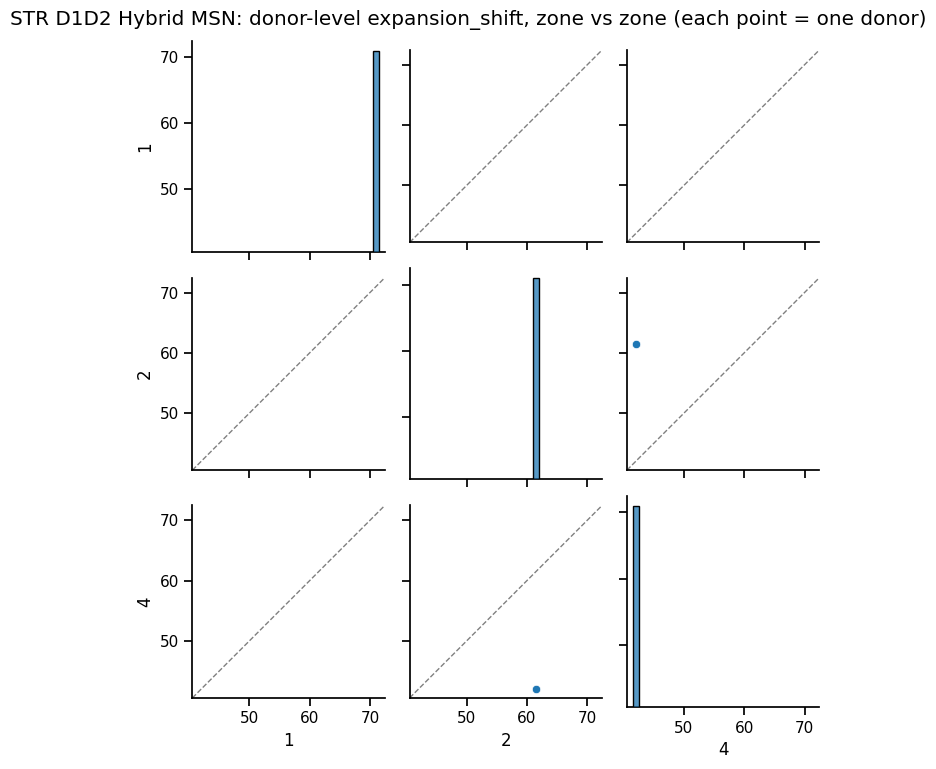

In [ ]:
for ct in ct_to_check:
    sub = celltype_zone_results[celltype_zone_results["celltype"] == ct]
    zone_df = sub.pivot(index="DONOR", columns="zone", values="expansion_shift")

    if zone_df.shape[1] < 2:
        print(f"skipping {ct}: fewer than 2 zones with data")
        continue

    vmin, vmax = zone_df.min().min(), zone_df.max().max()
    pad = 0.05 * (vmax - vmin)
    lims = (vmin - pad, vmax + pad)

    g = sns.pairplot(zone_df)

    for i in range(zone_df.shape[1]):
        for j in range(zone_df.shape[1]):
            ax = g.axes[i, j]
            ax.set_xlim(lims)
            if i != j:
                ax.set_ylim(lims)
                ax.set_aspect("equal", adjustable="box")
                ax.axline((0, 0), slope=1, color="gray", linestyle="--", linewidth=1, zorder=0)s

    g.fig.suptitle(f"{ct}: donor-level expansion_shift, zone vs zone (each point = one donor)", y=1.02)
    plt.show()

# Repeat Length per cell Vs Predicted DV score

### Calcualte DV score

ATTENTION: cannot be comapre caorss sampels as each sampel ahs been section in a differt dorsla.ventral position

In [56]:
CT_FOR_DEG_VARIABLE = "celltype_zoning"

In [57]:

# merge 
adata.obs["ct_for_deg"]=adata.obs[CT_FOR_DEG_VARIABLE].copy()
adata.obs[CT_FOR_DEG_VARIABLE].replace({"STR D2 Matrix MSN": "Matrix", "STR D1 Matrix MSN": "Matrix", "STRd D1 Striosome MSN": "Patch", "STRd D2 Striosome MSN": "Patch", "STR D1D2 Hybrid MSN": "eMSN"}, inplace=True)

/tmp/ipykernel_136673/1895442568.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  adata.obs[CT_FOR_DEG_VARIABLE].replace({"STR D2 Matrix MSN": "Matrix", "STR D1 Matrix MSN": "Matrix", "STRd D1 Striosome MSN": "Patch", "STRd D2 Striosome MSN": "Patch", "STR D1D2 Hybrid MSN": "eMSN"}, inplace=True)


In [58]:
adata.var.index = adata.var["gene_symbol"].copy()

In [59]:
# Genes whose Matrix/Patch spatial gradient (health vs XDP, from the BICAN spatial-spline
# analysis) is strong AND agrees in sign in BOTH conditions - i.e. disease-invariant spatial
# markers. Deliberately NOT genes whose gradient differs between health/XDP: those are
# candidate DEG hits themselves, and scoring cells with the genes being tested would regress
# a gene's DE signal out against itself.

CORR_DIR = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/genes_correlation"
STABLE_GRAD_THR           = 0.2   # minimum |rho| in EACH condition to count as "has gradient"
STABLE_GRAD_PADJ_THR      = 0.05
STABLE_GRAD_MIN_PCT_EXPR  = 0.20
STABLE_GRAD_MIN_MEAN_EXPR = 0.10

df_corr_health = pd.read_csv(f"{CORR_DIR}/df_corr.csv", index_col=0)
df_corr_xdp    = pd.read_csv(f"{CORR_DIR}/df_corr_xdp.csv", index_col=0)
common_genes   = df_corr_health.index.intersection(df_corr_xdp.index)

stable_grad_weight = {}   # ct -> Series(gene -> weight), weight = mean(rho_health, rho_XDP)
for ct in ["Matrix", "Patch", "eMSN"]:
    dfh, dfx = df_corr_health.loc[common_genes], df_corr_xdp.loc[common_genes]
    rho_h, rho_x = dfh[f"rho_{ct}"], dfx[f"rho_{ct}"]

    reliable_h = (dfh[f"padj_{ct}"] < STABLE_GRAD_PADJ_THR) & (dfh[f"pct_expr_{ct}"] >= STABLE_GRAD_MIN_PCT_EXPR) & (dfh[f"mean_expr_{ct}"] >= STABLE_GRAD_MIN_MEAN_EXPR)
    reliable_x = (dfx[f"padj_{ct}"] < STABLE_GRAD_PADJ_THR) & (dfx[f"pct_expr_{ct}"] >= STABLE_GRAD_MIN_PCT_EXPR) & (dfx[f"mean_expr_{ct}"] >= STABLE_GRAD_MIN_MEAN_EXPR)

    stable = (
        (rho_h.abs() >= STABLE_GRAD_THR) & (rho_x.abs() >= STABLE_GRAD_THR) &
        (np.sign(rho_h) == np.sign(rho_x)) &
        reliable_h & reliable_x
    ).fillna(False)

    genes_ct = common_genes[stable]
    stable_grad_weight[ct] = pd.concat([rho_h[genes_ct], rho_x[genes_ct]], axis=1).mean(axis=1)
    print(f"{ct}: {len(genes_ct)} stable gradient genes (agree in sign, health & XDP)")

stable_grad_weight


Matrix: 339 stable gradient genes (agree in sign, health & XDP)
Patch: 163 stable gradient genes (agree in sign, health & XDP)
eMSN: 231 stable gradient genes (agree in sign, health & XDP)


{'Matrix': ABHD12B    0.292252
 ABI3BP    -0.314378
 ABLIM1    -0.445626
 ACTG1     -0.258578
 ADAM12     0.395667
              ...   
 YWHAZ     -0.222178
 ZBTB20    -0.357788
 ZMAT4      0.262138
 ZNF385B    0.615598
 ZNF706    -0.222404
 Length: 339, dtype: float64,
 'Patch': ABI3BP    -0.239441
 ABLIM1    -0.373840
 ADCY5      0.304601
 ADRB1     -0.254576
 AFF3       0.308055
              ...   
 WSB1      -0.207514
 ZBTB20    -0.342757
 ZDHHC23   -0.271289
 ZNF385B    0.425977
 ZNF706    -0.218994
 Length: 163, dtype: float64,
 'eMSN': ADARB2       0.274372
 ADGRB3-DT   -0.333795
 AFF3         0.247025
 AK5         -0.324430
 ANKRD29      0.256143
                ...   
 TTLL11       0.384468
 UNC5C       -0.416131
 WLS          0.414881
 ZBTB20      -0.230607
 ZNF385B      0.500982
 Length: 231, dtype: float64}

In [79]:
from scipy import sparse
import os
def calc_gradient_score(adata, gene_weights, ct_col="ct_for_deg", score_col="gradient_score"):
    """Score every cell by its predicted position along the Matrix/Patch dorsal-ventral
    spatial gradient, using per-cell-type gene weights (dict: ct -> Series[gene -> weight],
    weight = mean spatial rho in health & XDP - see "Define gradient genes" above).

    ATTENTION: adata.X must be raw counts.
    ATTENTION: cells whose ct_col value isn't a key of `gene_weights` get NaN (e.g. glia).

    Each gene is z-scored across cells of its own cell type before being weighted by rho, so
    a highly-expressed-but-weakly-correlated gene can't dominate a lowly-expressed-but-
    strongly-correlated one purely by scale - only how informative the gene actually is about
    position (its rho) determines its contribution to the score.
    """

    adata.X = adata.layers["counts"].copy()
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)

    adata.obs[score_col] = np.nan

    for ct, weight in gene_weights.items():
        cell_mask = (adata.obs[ct_col] == ct).values
        if cell_mask.sum() == 0:
            continue

        genes_here = [g for g in weight.index if g in adata.var_names]
        print(f"{ct}: scoring {cell_mask.sum()} cells with {len(genes_here)}/{len(weight)} gradient genes found in adata")

        X = adata[cell_mask, genes_here].X
        X = X.toarray() if sparse.issparse(X) else np.asarray(X)
        X = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-9)   # z-score per gene, within this cell type

        adata.obs.loc[cell_mask, score_col] = X @ weight.loc[genes_here].values

    adata.X = adata.layers["counts"].copy()

    return adata


In [78]:
# save_csv_path = f"{os.path.dirname(ADATA_PATH)}/gradient_scores.csv"

# if not os.path.exists(save_csv_path):
adata.X = adata.layers["counts"].copy()  # use raw counts for score calculation

adata = calc_gradient_score(adata, stable_grad_weight, ct_col=CT_FOR_DEG_VARIABLE)


# adata.obs[["gradient_score"]].to_csv(save_csv_path)
# else:
#     df_scores = pd.read_csv(save_csv_path, index_col=0)
#     adata.obs = adata.obs.merge(df_scores, how="left", left_index=True, right_index=True, validate="one_to_one")

# only Matrix/Patch cells are expected to have a score - other cell types are outside the
# scope of stable_grad_weight (glia etc. were never spatially gradient-tested) and stay NaN
assert not adata.obs.loc[adata.obs[CT_FOR_DEG_VARIABLE].isin(stable_grad_weight.keys()), "gradient_score"].isna().any(), \
    "Some Matrix/Patch cells have no gradient score!"


Matrix: scoring 9263 cells with 330/339 gradient genes found in adata
Patch: scoring 1890 cells with 160/163 gradient genes found in adata
eMSN: scoring 367 cells with 226/231 gradient genes found in adata


2026-10-16 15:11:08 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-16 15:11:08 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


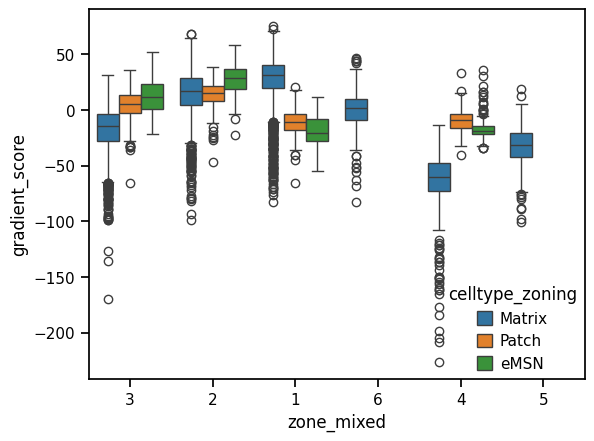

In [80]:
sns.boxplot(data=adata.obs[adata.obs[CT_FOR_DEG_VARIABLE].isin(["eMSN", "Matrix", "Patch"])],
            x="zone_mixed", y="gradient_score", hue=CT_FOR_DEG_VARIABLE)
plt.show()

### Compare 2 scores

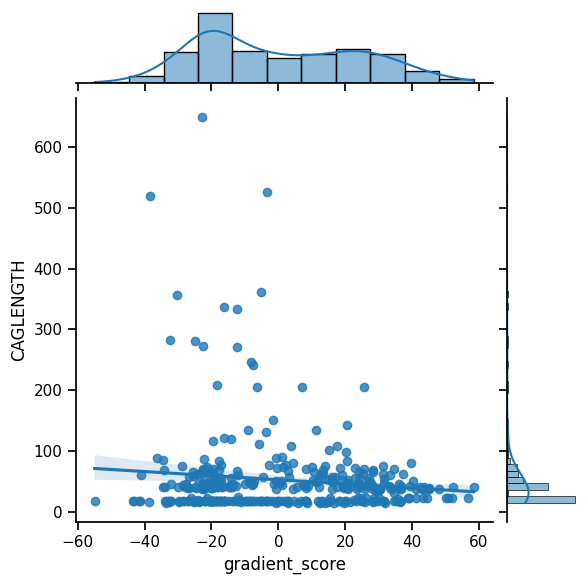

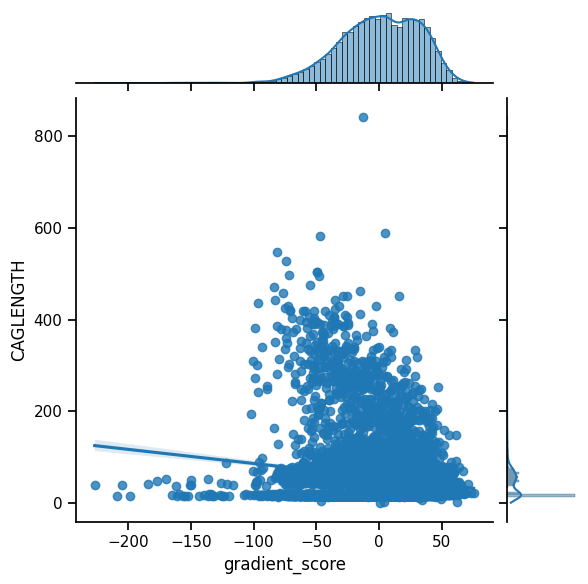

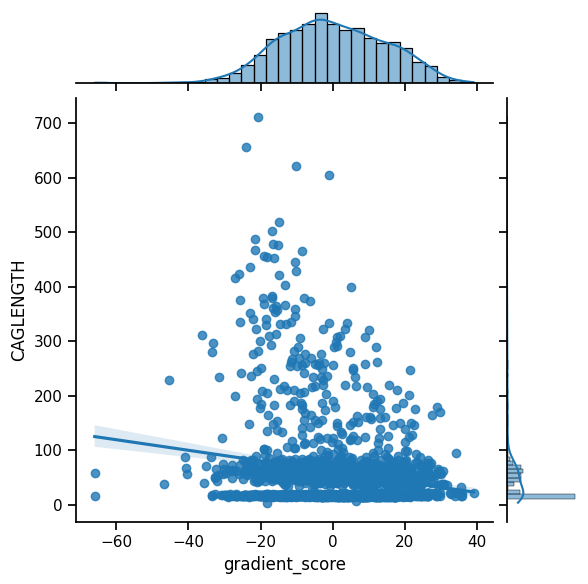

In [81]:
import seaborn as sns

for ct in ["eMSN", "Matrix", "Patch"]:

    sns.jointplot(adata[
            (adata.obs[CT_FOR_DEG_VARIABLE] == ct)
        ].obs , x="gradient_score", y="CAGLENGTH", kind="reg")
    plt.show()




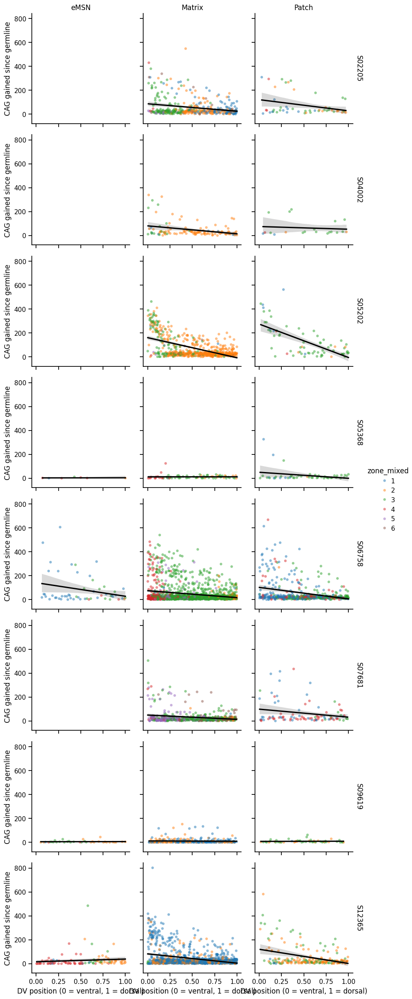

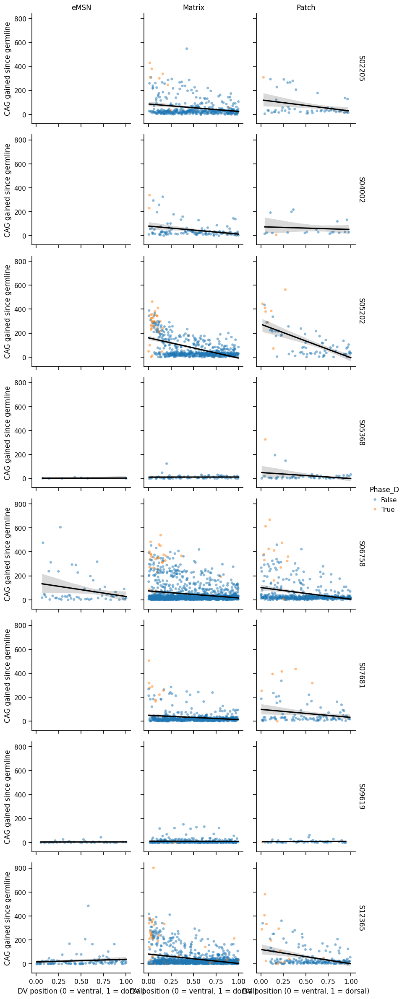

In [85]:
import seaborn as sns
import matplotlib.pyplot as plt

cts = ["eMSN", "Matrix", "Patch"]
CT = CT_FOR_DEG_VARIABLE

obs = adata.obs.copy()

# Selcet cell types for which we clauclte DV score
df = obs[obs[CT].isin(cts)].copy()

# Orient, then rank within donor x cell type (before any CAG filtering)
df["gradient_rank"] = (
    df.groupby(["DONOR", CT], observed=True)["gradient_score"].rank(pct=True)
)

# Exclude cells that   
    # capture no HTT RNA ---> Not cag length
    # capture onyl GER alleel of RNA --> cant see real 
# NX EXP germliene is differt for each cell
df = df[df["CAGLENGTH"] >= df["EXP_germline"]]   # also drops NaN CAG and controls

# Remove 
# q99 = df.groupby(["DONOR", CT], observed=True)["CAGLENGTH"].transform(lambda s: s.quantile(0.99))
# df = df[df["CAGLENGTH"] <= q99].copy()

# trnafporm into expanstion
df["expansion"] = df["CAGLENGTH"] - df["EXP_germline"]

n = df.groupby(["DONOR", CT], observed=True)["expansion"].transform("size")
df = df[n >= 5]

adata.obs["gradient_rank"] = df["gradient_rank"]
adata.obs["expansion"] = df["expansion"]


# g = sns.lmplot(
#     data=df, x="gradient_rank", y="expansion",
#     row="DONOR", col=CT, col_order=cts, hue="Phase_D",
#     #lowess=True,  #It slides along the x-axis and fits a small local trend in each region, then joins them
#     height=3, aspect=1,
#     scatter_kws={"s": 5, "alpha": 0.5},
#     facet_kws={"sharex": True, "sharey": True, "margin_titles": True},
# )
# g.set_axis_labels("DV position (0 = ventral, 1 = dorsal)", "CAG gained since germline")
# g.set_titles(row_template="{row_name}", col_template="{col_name}")
# plt.show()


# colr phase D cells too
LABEL = "Phase_D"   # your label column
LABEL = "zone_mixed"   # your label column


order = sorted(df[LABEL].dropna().unique())
pal = dict(zip(order, sns.color_palette("tab10", len(order))))

g = sns.FacetGrid(
    df, row="DONOR", col=CT, col_order=cts,
    height=3, aspect=1, sharex=True, sharey=True, margin_titles=True,
)

# Colored dots, one color per label
g.map_dataframe(sns.scatterplot, x="gradient_rank", y="expansion",
                hue=LABEL, hue_order=order, palette=pal,
                s=20, alpha=0.5, linewidth=0)

# One regression line per panel, using all cells
g.map_dataframe(sns.regplot, x="gradient_rank", y="expansion",
                scatter=False, color="black")

g.add_legend(title=LABEL)
g.set_axis_labels("DV position (0 = ventral, 1 = dorsal)", "CAG gained since germline")
g.set_titles(row_template="{row_name}", col_template="{col_name}")
plt.show()


#####################################################

LABEL = "Phase_D"   # your label column

order = sorted(df[LABEL].dropna().unique())
pal = dict(zip(order, sns.color_palette("tab10", len(order))))

g = sns.FacetGrid(
    df, row="DONOR", col=CT, col_order=cts,
    height=3, aspect=1, sharex=True, sharey=True, margin_titles=True,
)

# Colored dots, one color per label
g.map_dataframe(sns.scatterplot, x="gradient_rank", y="expansion",
                hue=LABEL, hue_order=order, palette=pal,
                s=20, alpha=0.5, linewidth=0)

# One regression line per panel, using all cells
g.map_dataframe(sns.regplot, x="gradient_rank", y="expansion",
                scatter=False, color="black")

g.add_legend(title=LABEL)
g.set_axis_labels("DV position (0 = ventral, 1 = dorsal)", "CAG gained since germline")
g.set_titles(row_template="{row_name}", col_template="{col_name}")
plt.show()

In [89]:
# Waht are other cells ventral (low dv score) but high CAG repeat that are nto pahse D

adata.obs["ventral_high_CAG_not_Phase_D"] = (
    (adata.obs["gradient_rank"] < 0.25) &
    (adata.obs["expansion"] > 200) &
    (adata.obs["Phase_D"] != True)
)

# CHeck phase D

In [90]:
from utils import label_mapping_utils as lmu


adata_msn = adata[adata.obs[CT_FOR_DEG_VARIABLE].isin(["Matrix", "Patch"])].copy()


leiden_cluster_names = lmu.preprocess_common_pipeline(adata_msn, leiden_name="_all_cells", integrate_with_harmony=True, batch_key="DONOR", 
                                                      resolutions=[0.1, 0.5, 1.0, 1.5])

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...
Running Harmony...
Running PCA before Harmony...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
2026-10-16 19:28:54,180 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-16 19:28:54 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-16 19:28:54,181 - harmonypy - INFO -   Parameters:
2026-10-16 19:28:54 | [INFO]   Parameters:
2026-10-16 19:28:54,182 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-16 19:28:54 | [INFO]     max_iter_harmony: 30
2026-10-16 19:28:54,183 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-16 19:28:54 | [INFO]     max_iter_kmeans: 20
2026-10-16 19:28:54,184 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-16 19:28:54 | [INFO]     epsilon_cluster: 1e-05
2026-10-16 19:28:54,185 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-16 19:28:54 | [INFO]     epsilon_harmony: 0.0001
2026-10-16 19:28:54,186 - harmonypy - INFO -     nclust: 100
2026-1

Running Harmony batch correction...


2026-10-16 19:28:54,448 - harmonypy - INFO - KMeans initialization complete.
2026-10-16 19:28:54 | [INFO] KMeans initialization complete.
2026-10-16 19:28:54,454 - harmonypy - INFO - Iteration 1 of 30
2026-10-16 19:28:54 | [INFO] Iteration 1 of 30
2026-10-16 19:28:54,839 - harmonypy - INFO - Iteration 2 of 30
2026-10-16 19:28:54 | [INFO] Iteration 2 of 30
2026-10-16 19:28:55,232 - harmonypy - INFO - Iteration 3 of 30
2026-10-16 19:28:55 | [INFO] Iteration 3 of 30
2026-10-16 19:28:55,613 - harmonypy - INFO - Iteration 4 of 30
2026-10-16 19:28:55 | [INFO] Iteration 4 of 30
2026-10-16 19:28:56,012 - harmonypy - INFO - Iteration 5 of 30
2026-10-16 19:28:56 | [INFO] Iteration 5 of 30
2026-10-16 19:28:56,400 - harmonypy - INFO - Iteration 6 of 30
2026-10-16 19:28:56 | [INFO] Iteration 6 of 30
2026-10-16 19:28:56,741 - harmonypy - INFO - Iteration 7 of 30
2026-10-16 19:28:56 | [INFO] Iteration 7 of 30
2026-10-16 19:28:56,997 - harmonypy - INFO - Iteration 8 of 30
2026-10-16 19:28:56 | [INFO] 

Z_corr shape: (11153, 50), n_obs: 11153
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


In [91]:
import numpy as np
import pandas as pd
import scipy.sparse as sp

x = adata_msn[:, "CDKN2A"].layers["log1p_norm"]
x = x.toarray().ravel() if sp.issparse(x) else np.asarray(x).ravel()

high = pd.Series(x > 0.3, index=adata_msn.obs_names)
adata.obs["Phase_D"] = high.reindex(adata.obs_names, fill_value=False).astype(bool)
adata_msn.obs["Phase_D"] = high.astype(bool)

... storing 'celltype_zoning' as categorical
... storing 'zone_mixed' as categorical
... storing 'ct_for_deg' as categorical


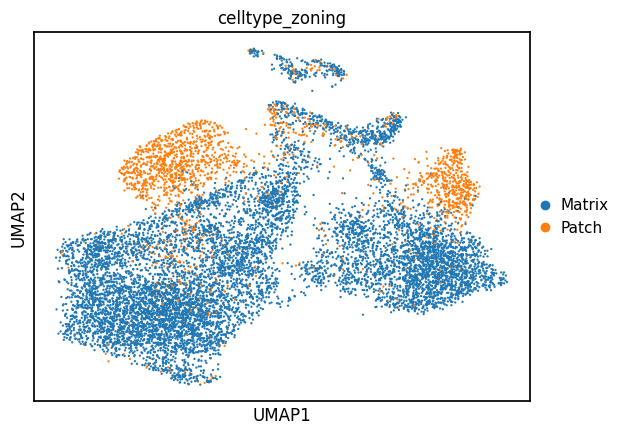

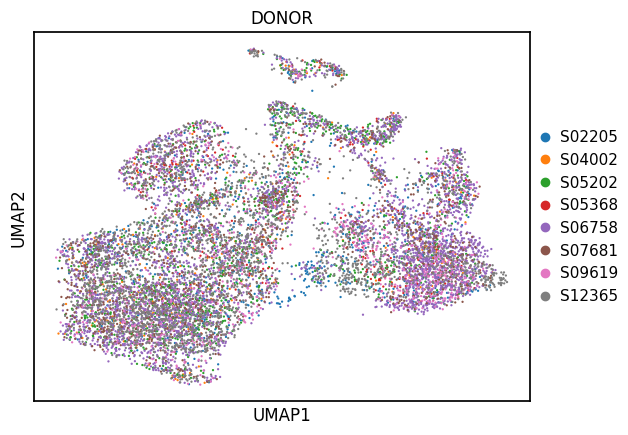

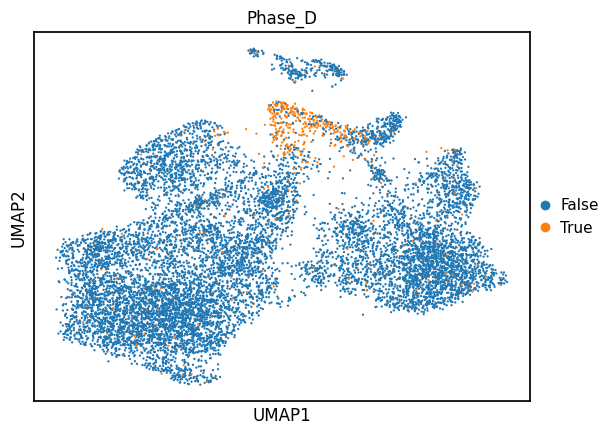

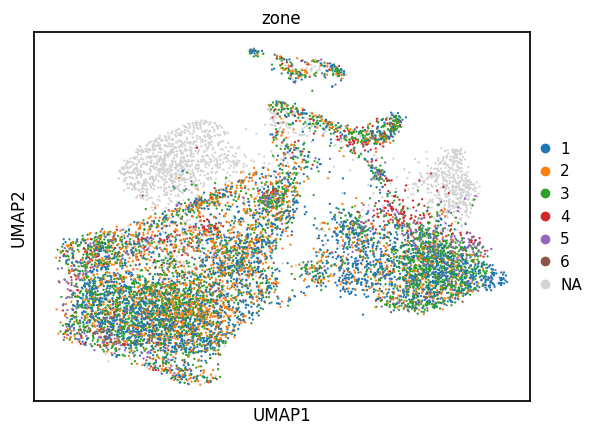

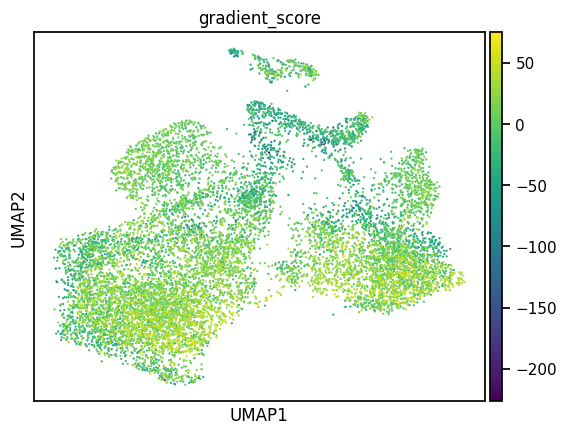

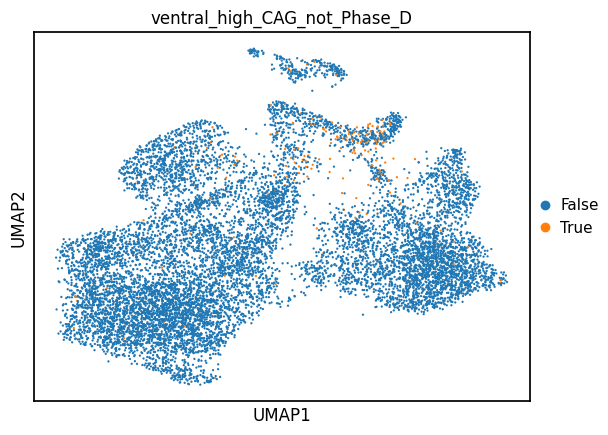

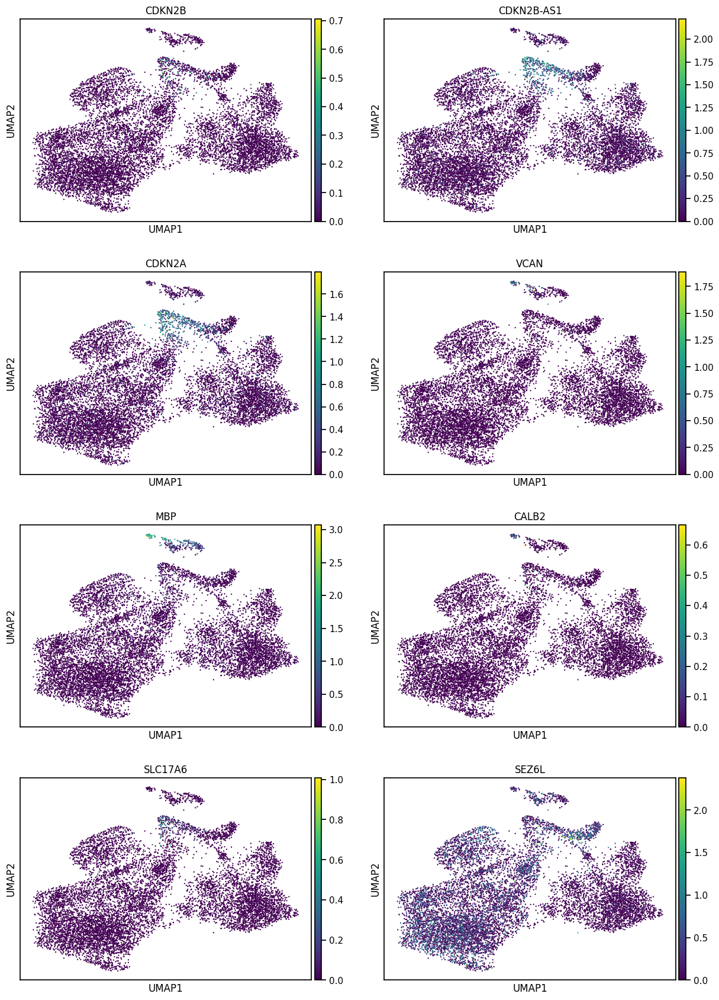

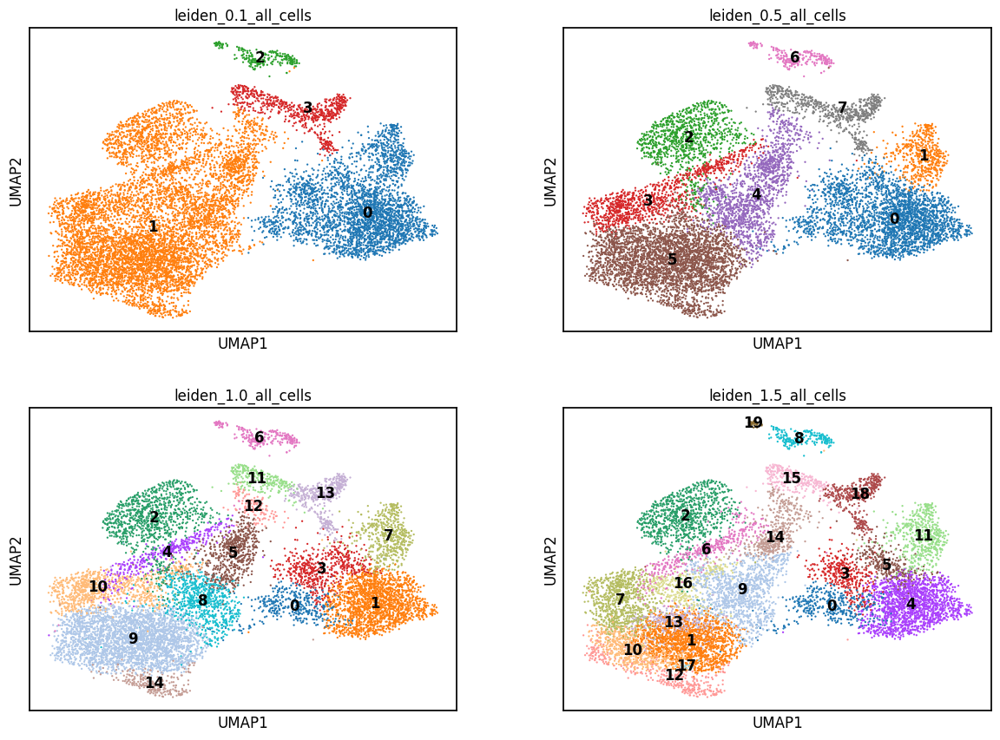

['leiden_0.1_all_cells',
 'leiden_0.5_all_cells',
 'leiden_1.0_all_cells',
 'leiden_1.5_all_cells']

In [92]:
sc.pl.umap(adata_msn,color=CT_FOR_DEG_VARIABLE)
sc.pl.umap(adata_msn,color="DONOR")
sc.pl.umap(adata_msn,color="Phase_D")
sc.pl.umap(adata_msn,color="zone")
sc.pl.umap(adata_msn,color="gradient_score")
sc.pl.umap(adata_msn,color="ventral_high_CAG_not_Phase_D")
sc.pl.umap(adata_msn,color=["CDKN2B", "CDKN2B-AS1", "CDKN2A", "VCAN", "MBP", "CALB2", "SLC17A6", "SEZ6L"], layer="log1p_norm", ncols=2)
sc.pl.umap(adata_msn,color=leiden_cluster_names, ncols=2, legend_loc="on data")

leiden_cluster_names

In [40]:
# Wilcoxon
from utils import preprocessing
res = preprocessing.rank_markers_per_cluster(adata_msn, "leiden_1.5_all_cells", layer="log1p_norm", n_genes=20, markers=None)

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(20))

2026-10-16 14:22:05 | [INFO] cffi mode is CFFI_MODE.ANY
2026-10-16 14:22:05 | [INFO] R home found: /usr/lib/R
2026-10-16 14:22:05 | [INFO] R library path: /usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64
2026-10-16 14:22:05 | [INFO] LD_LIBRARY_PATH: /usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64
2026-10-16 14:22:05 | [INFO] Default options to initialize R: rpy2, --quiet, --no-save
2026-10-16 14:22:05 | [INFO] Environment variable "LD_LIBRARY_PATH" redefined by R and overriding existing variable. Current: "/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64", R: "/usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,SH3RF2,29.656273,2.720450,2.815304e-193,1.040058e-188,SH3RF2
1,NTRK2,28.966087,2.082647,1.760245e-184,3.251437e-180,NTRK2
2,ANKS1B,27.985308,0.843414,2.452693e-172,2.613935e-168,ANKS1B
3,TRPS1,27.980198,1.899886,2.830236e-172,2.613935e-168,TRPS1
4,JARID2,26.788589,1.486972,4.388605e-158,3.242564e-154,JARID2
5,PRKCB,26.226049,1.072968,1.341136e-151,8.257600e-148,PRKCB
6,HOMER1,26.218096,1.349306,1.652676e-151,8.722117e-148,HOMER1
7,UBASH3B,26.028246,2.645963,2.372457e-149,1.095571e-145,UBASH3B
8,GPR158,25.747293,0.885680,3.456423e-146,1.418785e-142,GPR158
9,FNDC3A,25.416149,1.120921,1.672055e-142,6.177072e-139,FNDC3A


Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,BACH2,41.828297,3.386552,0.000000e+00,0.000000e+00,BACH2
1,RELN,39.886940,1.829754,0.000000e+00,0.000000e+00,RELN
2,KHDRBS3,36.304195,2.027480,1.389098e-288,5.701938e-285,KHDRBS3
3,PTPRQ,35.954990,2.946978,4.229722e-283,1.420533e-279,PTPRQ
4,FOXP2,35.895874,1.820899,3.542613e-282,1.006729e-278,FOXP2
5,SEMA5B,33.862431,2.438400,2.381583e-251,4.887935e-248,SEMA5B
6,KCNIP1,33.325405,2.045491,1.655182e-243,3.218285e-240,KCNIP1
7,LSAMP,32.744244,0.837164,3.666704e-235,6.157229e-232,LSAMP
8,CDH18,32.161167,1.253599,6.165445e-227,9.490418e-224,CDH18
9,GRIA1,31.808825,0.731256,4.887616e-222,7.222528e-219,GRIA1


Cluster 2:


... (27 outputs left out)

Cluster 17:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,SPTBN4,10.799356,0.458498,3.466258e-27,8.408600e-24,SPTBN4
1,PDZD2,10.122906,0.319958,4.372376e-24,4.615105e-21,PDZD2
2,GNG7,9.966801,0.395229,2.129792e-23,1.967022e-20,GNG7
3,SRRM3,9.563683,0.356617,1.136393e-21,7.206770e-19,SRRM3
4,MIAT,9.541966,0.473133,1.401499e-21,8.350898e-19,MIAT
5,HTT,9.421234,0.484087,4.458171e-21,2.422033e-18,HTT
6,MMD2,9.064425,0.509665,1.252637e-19,5.141797e-17,MMD2
7,SLC35F3,8.882782,0.294430,6.520849e-19,2.210089e-16,SLC35F3
8,ARNT2,8.816591,0.276171,1.179975e-18,3.687303e-16,ARNT2
9,PI4KA,8.772833,0.309779,1.742272e-18,5.185568e-16,PI4KA


Cluster 12:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
